# CP2 — Laboratorio: implementar y comparar metaheurísticas

En Inteligencia Artificial existen diferentes métodos para resolver problemas de optimización. Algunos exploran sistemáticamente un espacio de soluciones, mientras que otros utilizan estrategias heurísticas para encontrar soluciones de buena calidad sin necesidad de examinar todas las alternativas.

Las metaheurísticas son procedimientos generales de búsqueda que permiten explorar espacios de soluciones potencialmente muy grandes. Entre ellas se encuentran los algoritmos genéticos y el recocido simulado.

Sin embargo, no existe una metaheurística que sea siempre superior a todas las demás para cualquier problema. Su rendimiento depende de las características del problema, de la representación de las soluciones, de la función objetivo, de los parámetros utilizados y del presupuesto computacional disponible.

Por tanto, no basta con ejecutar dos algoritmos y seleccionar el que produzca el mejor resultado en una ejecución particular. Para comparar su comportamiento de manera rigurosa es necesario diseñar un experimento que permita distinguir las diferencias sistemáticas de las variaciones debidas al azar.

En esta práctica se utilizará un problema simplificado del rover autónomo. Se implementarán y compararán dos metaheurísticas para optimizar una ruta, utilizando varias instancias del problema, múltiples repeticiones, semillas aleatorias y un presupuesto de evaluación común.

### Descripción del problema
El rover debe salir de una base, visitar un conjunto de puntos de interés y regresar a la base. Cada desplazamiento tiene un coste, que puede representar distancia, tiempo o consumo energético.
El objetivo consiste en encontrar una ruta de coste mínimo.
Para simplificar el problema, se proporcionará una matriz de distancias entre los puntos. En esta versión de la práctica, el coste de desplazarse entre dos puntos no depende del orden en que se recorren ni de los recursos restantes del rover.
Se supone que:
- Existe una base identificada con el índice 0.
- Los demás índices representan puntos de interés.
- Cada punto de interés debe visitarse exactamente una vez.
- La ruta comienza y termina en la base.
- El coste total es la suma de los desplazamientos consecutivos.
Por ejemplo, para una ruta:
\[
R=(0,2,1,3,0)
\]
el coste será:
\[
C(R)=d_{0,2}+d_{2,1}+d_{1,3}+d_{3,0}
\]
donde \(d_{i,j}\) representa el coste de desplazarse desde el punto \(i\) hasta el punto \(j\).


### Ejercicio 1. Representación del problema

Antes de implementar una metaheurística, es necesario definir qué representa una solución y cómo se evalúa su calidad.

Actividad 1.1. Responde antes de ejecutar el código

a) ¿Qué representa una solución en este problema?

b) ¿Qué representa el valor devuelto por la función objetivo?

c) ¿Por qué se utiliza una función de minimización?

d) ¿Qué restricciones debe cumplir una ruta para considerarse factible?

e) ¿Por qué no sería suficiente comparar los algoritmos utilizando rutas de longitudes diferentes, si cada uno resuelve un problema distinto?

Actividad 1.2. Representación de una solución

Una solución se representará mediante una permutación de los puntos de interés, excluyendo la base.
Por ejemplo: R=(0,2,1,3,0)

La ruta completa será:
Base → Punto 3 → Punto 1 → Punto 4 → Punto 2 → Base

Esta representación garantiza que todos los puntos de interés aparecen exactamente una vez, siempre que la solución sea una permutación válida.

Actividad 1.3. Función objetivo

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from abc import ABC, abstractmethod
from typing import Any, Callable, List, Optional


def calcular_coste(ruta, distancias):
    """
    Calcula el coste total de una ruta.

    Parámetros
    ----------
    ruta : lista o array
        Permutación de los puntos de interés.
        No incluye la base, identificada con 0.

    distancias : array de numpy
        Matriz de costes entre los puntos.

    Retorna
    -------
    float
        Coste total de la ruta, incluyendo salida
        y regreso a la base.
    """
    ruta_completa = [0] + list(ruta) + [0]

    coste = 0

    for i in range(len(ruta_completa) - 1):
        origen = ruta_completa[i]
        destino = ruta_completa[i + 1]

        coste += distancias[origen, destino]

    return float(coste)

In [10]:
distancias_ejemplo = np.array([
    [0, 2, 9, 10],
    [2, 0, 6, 4],
    [9, 6, 0, 3],
    [10, 4, 3, 0]
], dtype=float)

ruta_ejemplo = [1, 2, 3]

coste = calcular_coste(
    ruta_ejemplo,
    distancias_ejemplo
)

print("Ruta:", [0] + ruta_ejemplo + [0])
print("Coste:", coste)

Ruta: [0, 1, 2, 3, 0]
Coste: 21.0


Preguntas: 

1. ¿Qué ocurriría con el coste si se modificara el orden de los puntos de interés?

2. ¿Cómo se podría construir la matriz de costes si los puntos de interés estuvieran situados en un mapa con obstáculos y terrenos de diferente coste?

### Ejercicio 2. Algoritmo genético

En este ejercicio se utilizarán cuatro componentes:

1. Población inicial: conjunto de rutas generadas aleatoriamente.

2. Selección: elección de individuos que actuarán como progenitores.

3. Cruce: combinación de dos rutas para generar descendientes.

4. Mutación: intercambio de dos puntos de interés dentro de una ruta.

Como el objetivo es minimizar el coste, las rutas con valores más bajos se consideran mejores.

In [ ]:
from metaheuristics import MetaHeuristic

class AlgoritmoGenetico(MetaHeuristic):

    def __init__(
        self,
        n_puntos,
        population_size=20,
        mutation_rate=0.2,
        seed=None
    ):

        self.n_puntos = n_puntos
        self.population_size = population_size
        self.mutation_rate = mutation_rate
        self.rng = np.random.default_rng(seed)

    def generar_individuo(self):

        return self.rng.permutation(
            np.arange(1, self.n_puntos)
        )

    def seleccionar(
        self,
        poblacion,
        valores,
        k=3
    ):
        """
        Selección por torneo.
        """
        indices = self.rng.integers(
            0,
            len(poblacion),
            size=k
        )

        mejor_indice = min(
            indices,
            key=lambda i: valores[i]
        )

        return poblacion[mejor_indice].copy()

    def cruzar(self, padre1, padre2):
        """
        Genera un descendiente a partir de dos progenitores.

        Debe utilizarse el operador de cruce por orden (OX),
        conservando la representación de permutación.

        TAREA: completar la implementación.
        """
        # COMPLETAR
        pass

    def mutar(self, individuo):
        """
        Aplica una mutación a una ruta con la probabilidad
        establecida por mutation_rate.

        TAREA: completar la implementación mediante el
        intercambio de dos posiciones distintas.
        """
        # COMPLETAR
        pass

    def solve(
        self,
        obj_func,
        distancias,
        generaciones=None
    ):

        poblacion = [
            self.generar_individuo()
            for _ in range(self.population_size)
        ]

        valores = [
            obj_func(ind, distancias)
            for ind in poblacion
        ]

        mejor_idx = int(np.argmin(valores))

        mejor_sol = poblacion[mejor_idx].copy()
        mejor_val = valores[mejor_idx]

        yield mejor_sol.copy(), mejor_val

        while True:

            nueva_poblacion = [
                mejor_sol.copy()
            ]

            while len(nueva_poblacion) < self.population_size:

                padre1 = self.seleccionar(
                    poblacion,
                    valores
                )

                padre2 = self.seleccionar(
                    poblacion,
                    valores
                )

                hijo = self.cruce(
                    padre1,
                    padre2
                )

                hijo = self.mutar(hijo)

                nueva_poblacion.append(hijo)

            poblacion = nueva_poblacion

            valores = [
                obj_func(ind, distancias)
                for ind in poblacion
            ]

            idx = int(np.argmin(valores))

            if valores[idx] < mejor_val:
                mejor_sol = poblacion[idx].copy()
                mejor_val = valores[idx]

            yield mejor_sol.copy(), mejor_val

Actividad 2.1. Explica por qué una ruta debe representarse como una permutación.

Actividad 2.2. Explica por qué no sería adecuado utilizar una mutación que sustituyera un punto de interés por otro elegido aleatoriamente, sin comprobar si ya aparece en la ruta.

Actividad 2.3. Identifica la función encargada de cada operación:

- Generar la población inicial.

- Seleccionar progenitores.

- Cruzar dos individuos.

- Mutar una ruta.

- Evaluar la calidad de una solución.

Actividad 2.4. Modifica el tamaño de la población y analiza qué sucede con el número de generaciones que pueden ejecutarse bajo un presupuesto fijo de evaluaciones.

Actividad 2.5. Justifica por qué debe utilizarse el mismo presupuesto de evaluaciones al comparar este algoritmo con otra metaheurística.

### Ejercicio 3. Recocido simulado

El recocido simulado parte de una solución inicial y genera soluciones vecinas. Si encuentra una solución mejor, la acepta. Si encuentra una peor, puede aceptarla con una probabilidad que depende de la diferencia de coste y de la temperatura actual.

La temperatura \(T\) controla la disposición del algoritmo a aceptar soluciones peores.
- Con una temperatura elevada, puede aceptar soluciones peores con mayor probabilidad.
- A medida que la temperatura disminuye, resulta menos probable aceptar movimientos desfavorables.
Esta estrategia permite explorar distintas regiones del espacio de soluciones y reduce la dependencia de la solución inicial.

In [ ]:
class RecocidoSimulado(MetaHeuristic):

    def __init__(
        self,
        n_puntos,
        temperatura_inicial=100.0,
        enfriamiento=0.995,
        temperatura_minima=0.01,
        seed=None
    ):

        self.n_puntos = n_puntos
        self.temperatura_inicial = temperatura_inicial
        self.enfriamiento = enfriamiento
        self.temperatura_minima = temperatura_minima

        self.rng = np.random.default_rng(seed)

    def generar_solucion_inicial(self):

        return self.rng.permutation(
            np.arange(1, self.n_puntos)
        )

    def generar_vecino(self, solucion):
        """
        Genera una solución vecina intercambiando
        dos posiciones de la ruta.

        TAREA: completar la implementación.
        """
        # COMPLETAR
        pass

    def solve(
        self,
        obj_func,
        distancias
    ):

        actual = self.generar_solucion_inicial()

        coste_actual = obj_func(
            actual,
            distancias
        )

        mejor = actual.copy()
        mejor_coste = coste_actual

        temperatura = self.temperatura_inicial

        yield mejor.copy(), mejor_coste

        while True:

            vecino = self.generar_vecino(actual)

            coste_vecino = obj_func(
                vecino,
                distancias
            )

            diferencia = coste_vecino - coste_actual

            if diferencia < 0:

                aceptar = True

            else:

                probabilidad = np.exp(
                    -diferencia / max(
                        temperatura,
                        1e-12
                    )
                )

                aceptar = (
                    self.rng.random()
                    < probabilidad
                )

            if aceptar:

                actual = vecino.copy()
                coste_actual = coste_vecino

            if coste_actual < mejor_coste:

                mejor = actual.copy()
                mejor_coste = coste_actual

            temperatura = max(
                temperatura * self.enfriamiento,
                self.temperatura_minima
            )

            yield mejor.copy(), mejor_coste

Actividad 3.1. Explica por qué el recocido simulado no acepta siempre una solución peor.

Actividad 3.2. ¿Qué efecto esperas que tenga una temperatura inicial más elevada?

Actividad 3.3. ¿Qué sucedería si la temperatura disminuyera demasiado rápido?

Actividad 3.4. ¿Por qué el algoritmo conserva la mejor solución encontrada, aunque acepte posteriormente una solución peor?

Actividad 3.5. Modifica el parámetro de enfriamiento y formula una hipótesis sobre su efecto en el resultado

### Ejercicio 4. Generar problemas reproducibles

Para comparar los algoritmos es necesario probarlos en más de una instancia. Si solo se utiliza un conjunto de puntos, las conclusiones pueden depender excesivamente de esa configuración particular.
En esta práctica se generarán tres instancias con 12 puntos en total: una base y 11 puntos de interés.
Se utilizarán coordenadas bidimensionales y la distancia euclidiana como coste de desplazamiento.

In [13]:
def generar_instancia(
    n_puntos=12,
    seed=42
):

    rng = np.random.default_rng(seed)

    coordenadas = rng.uniform(
        low=0,
        high=100,
        size=(n_puntos, 2)
    )

    distancias = np.zeros(
        (n_puntos, n_puntos)
    )

    for i in range(n_puntos):

        for j in range(n_puntos):

            distancias[i, j] = np.linalg.norm(
                coordenadas[i] - coordenadas[j]
            )

    return coordenadas, distancias

In [14]:
semillas_instancias = [101, 202, 303]

instancias = {}

for i, semilla in enumerate(
    semillas_instancias,
    start=1
):

    coordenadas, distancias = generar_instancia(
        n_puntos=12,
        seed=semilla
    )

    instancias[i] = {
        "coordenadas": coordenadas,
        "distancias": distancias
    }

print("Instancias generadas:", len(instancias))

Instancias generadas: 3


In [15]:
def dibujar_instancia(coordenadas, titulo):

    plt.figure(figsize=(7, 5))

    plt.scatter(
        coordenadas[1:, 0],
        coordenadas[1:, 1],
        label="Puntos de interés"
    )

    plt.scatter(
        coordenadas[0, 0],
        coordenadas[0, 1],
        marker="s",
        s=100,
        label="Base"
    )

    for i, (x, y) in enumerate(coordenadas):

        plt.annotate(
            str(i),
            (x, y),
            xytext=(4, 4),
            textcoords="offset points"
        )

    plt.title(titulo)
    plt.xlabel("Coordenada X")
    plt.ylabel("Coordenada Y")
    plt.legend()
    plt.grid(True)
    plt.show()

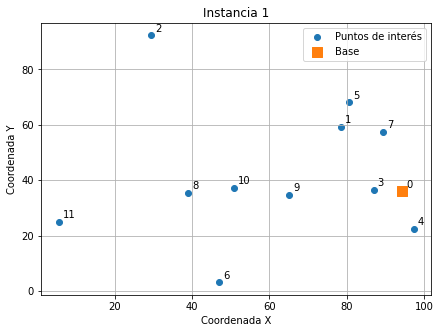

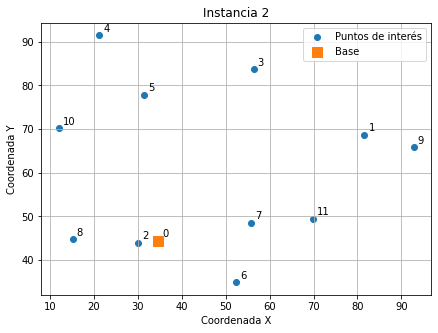

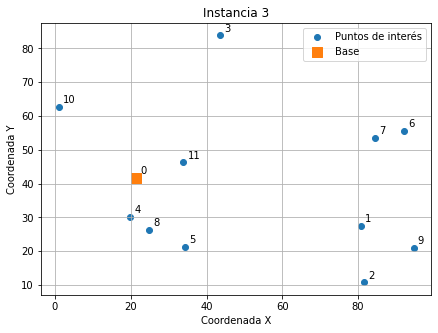

In [16]:
for numero, datos in instancias.items():

    dibujar_instancia(
        datos["coordenadas"],
        f"Instancia {numero}"
    )

Preguntas

1. ¿Por qué se generan varias instancias?

2. ¿Qué papel desempeñan las semillas?


#### 4.1 Ficha de diseño experimental

Antes de ejecutar el experimento definitivo, completa la siguiente tabla.

| Decisión | Respuesta |
|---|---|
| ¿Qué problema se optimiza? | |
| ¿Cuál es la función objetivo? | |
| ¿Qué algoritmos se comparan? | |
| ¿Qué condiciones se mantienen iguales? | |
| ¿Cuántas instancias se utilizarán? | |
| ¿Cuántas repeticiones se realizarán? | |
| ¿Cuál es el presupuesto por ejecución? | |
| ¿Qué semillas se utilizarán? | |
| ¿Cuál es la métrica principal? | |
| ¿Qué medidas de dispersión se calcularán? | |
| ¿Qué hipótesis se quiere contrastar? | |

In [ ]:
def ejecutar_experimento(
    instancias,
    repeticiones=10,
    presupuesto=5000
):

    registros = []

    for num_instancia, datos in instancias.items():

        distancias = datos["distancias"]
        n_puntos = len(distancias)

        for repeticion in range(repeticiones):

            semilla = (
                10000 * num_instancia
                + repeticion
            )

            print(
                f"Instancia {num_instancia} | "
                f"Repetición {repeticion + 1}/{repeticiones}"
            )

            # ----------------------------
            # Algoritmo genético
            # ----------------------------

            ga = AlgoritmoGenetico(
                n_puntos=n_puntos,
                population_size=20,
                mutation_rate=0.2,
                seed=semilla
            )

            resultado_ga = ga.evaluate(
                calcular_coste,
                max_evals=presupuesto,
                verbose=False,
                distancias=distancias
            )

            registros.append({
                "instancia": num_instancia,
                "repeticion": repeticion + 1,
                "semilla": semilla,
                "algoritmo": "Genético",
                "mejor_coste": resultado_ga.best_value,
                "evaluaciones": resultado_ga.total_evals,
                "tiempo": resultado_ga.total_time
            })

            # ----------------------------
            # Recocido simulado
            # ----------------------------

            sa = RecocidoSimulado(
                n_puntos=n_puntos,
                temperatura_inicial=100,
                enfriamiento=0.995,
                temperatura_minima=0.01,
                seed=semilla
            )

            resultado_sa = sa.evaluate(
                calcular_coste,
                max_evals=presupuesto,
                verbose=False,
                distancias=distancias
            )

            registros.append({
                "instancia": num_instancia,
                "repeticion": repeticion + 1,
                "semilla": semilla,
                "algoritmo": "Recocido simulado",
                "mejor_coste": resultado_sa.best_value,
                "evaluaciones": resultado_sa.total_evals,
                "tiempo": resultado_sa.total_time
            })

    return pd.DataFrame(registros)


In [ ]:
resultados = ejecutar_experimento(
    instancias=instancias,
    repeticiones=10,
    presupuesto=5000
)
print("Número de ejecuciones:", len(resultados))

resultados.head(10)

,instancia,repeticion,semilla,algoritmo,mejor_coste,evaluaciones,tiempo
0,1,1,10000,Genético,354.893557,5000,0.150461
1,1,1,10000,Recocido simulado,349.428068,5000,0.048115
2,1,2,10001,Genético,330.108826,5000,0.123307
3,1,2,10001,Recocido simulado,336.623118,5000,0.047671
4,1,3,10002,Genético,331.853131,5000,0.120389
5,1,3,10002,Recocido simulado,330.108826,5000,0.049050
6,1,4,10003,Genético,340.446646,5000,0.127237
7,1,4,10003,Recocido simulado,363.295403,5000,0.048842
8,1,5,10004,Genético,340.801442,5000,0.122484
9,1,5,10004,Recocido simulado,330.108826,5000,0.048653


In [ ]:
resultados.to_csv(
    "resultados_cp2.csv",
    index=False
)

In [25]:
resumen = (
    resultados
    .groupby(["instancia", "algoritmo"])["mejor_coste"]
    .agg(
        media="mean",
        desviacion="std",
        mediana="median",
        minimo="min",
        maximo="max"
    )
    .reset_index()
)

resumen

,instancia,algoritmo,media,desviacion,mediana,minimo,maximo
0,1,Genético,337.326543,8.050670,336.149888,330.108826,354.893557
1,1,Recocido simulado,340.635970,11.460115,336.623118,330.108826,363.295403
2,2,Genético,230.555642,3.701566,228.304101,228.304101,236.887123
3,2,Recocido simulado,255.685575,24.730358,255.310529,228.304101,302.371313
4,3,Genético,297.804098,2.366150,296.442761,296.005007,302.475803
5,3,Recocido simulado,317.776413,6.457558,316.508723,313.363098,334.420898


Preguntas

1. ¿Qué algoritmo obtuvo la menor media?
2. ¿Qué algoritmo presentó la menor desviación estándar?
3. ¿Coincide el algoritmo con mejor media con el que obtuvo el mejor resultado individual?
4. ¿Existe alguna instancia en la que cambie el algoritmo con mejor rendimiento?
5. ¿Qué información perderíamos si solo informáramos del mínimo?

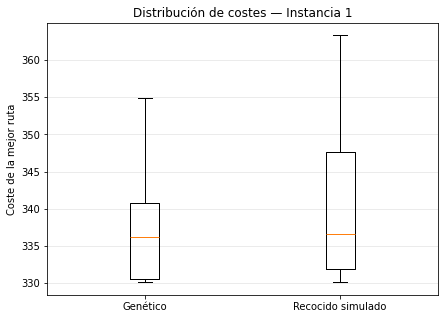

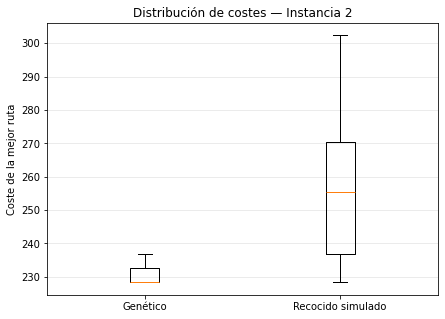

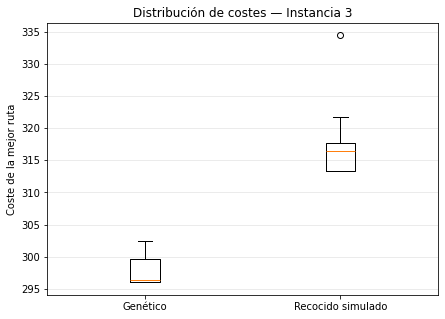

In [26]:
for num_instancia in sorted(
    resultados["instancia"].unique()
):

    datos = resultados[
        resultados["instancia"] == num_instancia
    ]

    grupos = [
        datos.loc[
            datos["algoritmo"] == algoritmo,
            "mejor_coste"
        ].to_numpy()
        for algoritmo in [
            "Genético",
            "Recocido simulado"
        ]
    ]

    plt.figure(figsize=(7, 5))

    plt.boxplot(
        grupos,
        tick_labels=[
            "Genético",
            "Recocido simulado"
        ]
    )

    plt.title(
        f"Distribución de costes — Instancia {num_instancia}"
    )

    plt.ylabel("Coste de la mejor ruta")
    plt.grid(axis="y", alpha=0.3)
    plt.show()

Preguntas de interpretación

1. ¿Qué algoritmo presenta la mediana más baja?
2. ¿Qué algoritmo presenta menor dispersión?
3. ¿Se observan valores extremos?
4. ¿Las diferencias entre algoritmos son similares en las tres instancias?
5. ¿Qué conclusiones pueden extraerse del gráfico y cuáles no están justificadas solamente por su inspección visual?

In [27]:
resumen_tiempo = (
    resultados
    .groupby(["instancia", "algoritmo"])["tiempo"]
    .agg(
        media="mean",
        desviacion="std",
        mediana="median"
    )
    .reset_index()
)

resumen_tiempo

,instancia,algoritmo,media,desviacion,mediana
0,1,Genético,0.128498,0.009226,0.125569
1,1,Recocido simulado,0.049431,0.001899,0.048786
2,2,Genético,0.126307,0.005816,0.127061
3,2,Recocido simulado,0.049279,0.001529,0.048576
4,3,Genético,0.123688,0.007598,0.121114
5,3,Recocido simulado,0.048538,0.001207,0.047930


Pregunta:

1. ¿Cuál de las dos metaheurísticas presenta un mejor comportamiento para el problema estudiado?

Redacta un párrafo que explique qué relación existe entre los resultados obtenidos y la idea de que no hay un algoritmo de optimización que sea el mejor para todos los problemas.

La conclusión debe apoyarse en los resultados de las tres instancias. Si un algoritmo obtiene mejores resultados en todas ellas, no significa que hayas demostrado que es universalmente superior: únicamente has observado que se comporta mejor bajo las condiciones experimentales estudiadas.

Observación: alcanzar el límite de evaluaciones no significa que el algoritmo haya fallado en resolver el problema. Significa que se ha agotado el presupuesto establecido para la ejecución.

## Entregables de la CP2
Cada estudiante deberá entregar:
1. Notebook ejecutable
2. Archivo de resultados
Se entregará el archivo:
resultados_cp2.csv
3. La Ficha de Diseño Experimental (la tabla del Ejercicio 4.1) especificando qué instancias usarían, el presupuesto fijo, las repeticiones, las semillas, las métricas principales y las medidas de dispersión antes de ejecutar los algoritmos. 
Debe contener los resultados de las ejecuciones realizadas, las semillas y los valores de las métricas registradas.


Informe Escrito (Máximo 2 páginas, PDF):

Sección 1: Problema y Diseño Experimental: Breve definición del problema en su Proyecto 1 y síntesis del protocolo seguido.

Sección 2: Resultados Tabulares y Gráficos: Tabla resumen comparativa con media y desviación estándar / mediana / min / max (no solo el mejor resultado aislado) y al menos un gráfico de distribución (p. ej., boxplots por instancia).

Sección 3: Discusión y Análisis Crítico:

¿Qué ocurre con la supuesta ventaja de un algoritmo cuando se analiza la dispersión y la media en lugar de la mejor corrida?

Discusión detonante: ¿Cuál algoritmo es mejor? ¿Bajo qué presupuesto, qué tipo de instancias y según qué criterio?

Sección 4: Conclusiones: Interpretación de los hallazgos en relación con el principio de No Free Lunch y limitaciones del estudio.